In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

In [4]:
df = pd.read_csv("2015.csv")
df = df.drop(["Region","Country", "Happiness Rank"], axis=1)
df = pd.get_dummies(df, drop_first=True)
X = df.drop(["Happiness Score"], axis=1)
y = df["Happiness Score"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train=scaler.fit_transform(X_train) 
X_test=scaler.transform(X_test)

corr_matrix = X.corr()

display(corr_matrix.round(2))

,Standard Error,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual
Standard Error,1.00,-0.22,-0.12,-0.31,-0.13,-0.18,-0.09,0.08
Economy (GDP per Capita),-0.22,1.00,0.65,0.82,0.37,0.31,-0.01,0.04
Family,-0.12,0.65,1.00,0.53,0.44,0.21,0.09,0.15
Health (Life Expectancy),-0.31,0.82,0.53,1.00,0.36,0.25,0.11,0.02
Freedom,-0.13,0.37,0.44,0.36,1.00,0.49,0.37,0.06
Trust (Government Corruption),-0.18,0.31,0.21,0.25,0.49,1.00,0.28,-0.03
Generosity,-0.09,-0.01,0.09,0.11,0.37,0.28,1.00,-0.10
Dystopia Residual,0.08,0.04,0.15,0.02,0.06,-0.03,-0.10,1.00


In [5]:
lr = LinearRegression()
lr.fit(X_train, y_train)

alphas_to_test = [0.1, 1.0, 10.0, 100.0, 1000.0, 2000.0, 3000.0, 5000.0, 10000.0]
ridge_cv = RidgeCV(alphas=alphas_to_test)
ridge_cv.fit(X_train, y_train)


lasso_cv =LassoCV(alphas=alphas_to_test, random_state=42)
lasso_cv.fit(X_train, y_train)
lasso =Lasso(alpha=5000.0, random_state=42)
lasso.fit(X_train, y_train)
print(f"alpha l2= {ridge_cv.alpha_}")
print(f"alpha l1 = {lasso_cv.alpha_}")
print("Веса OLS")
print(np.round(lr.coef_, 0))
print("Веса Ridge (L2)")
print(np.round(ridge_cv.coef_, 0))
print("Веса Lasso (L1)")
print(np.round(lasso_cv.coef_, 0))
print("Веса Lasso (L1) (alpha = 5000)")
print(np.round(lasso.coef_, 0))


alpha l2= 0.1
alpha l1 = 0.1
Веса OLS
[-0.  0.  0.  0.  0.  0.  0.  1.]
Веса Ridge (L2)
[-0.  0.  0.  0.  0.  0.  0.  1.]
Веса Lasso (L1)
[-0.  0.  0.  0.  0.  0.  0.  0.]
Веса Lasso (L1) (alpha = 5000)
[0. 0. 0. 0. 0. 0. 0. 0.]


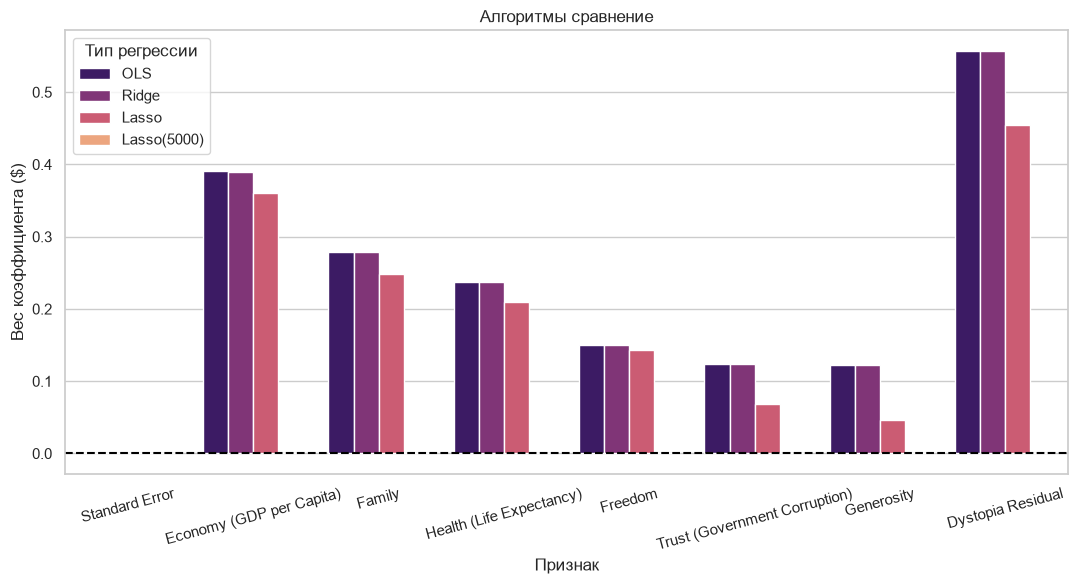

In [6]:
weights_df = pd.DataFrame(
    {
        "Признак" : X.columns,
        "OLS" : lr.coef_,
        "Ridge" : ridge_cv.coef_,
        "Lasso" : lasso_cv.coef_,
        "Lasso(5000)" : lasso.coef_,
    }
)
weights_melted = weights_df.melt(
    id_vars="Признак", var_name="Модель", value_name="Влияние на счастье (Вес)" 
)
plt.figure(figsize=(11,6))
sns.barplot(
    data=weights_melted,
    x="Признак",
    y="Влияние на счастье (Вес)",
    hue="Модель",
    palette="magma"
)

plt.axhline(0, color="black", lw=1.5, ls="--")
plt.title("Алгоритмы сравнение")
plt.ylabel("Вес коэффициента ($)", fontsize=12)
plt.xticks(rotation=15)
plt.legend(title="Тип регрессии")
plt.tight_layout()
plt.show()


Нашли признаки от которых зависит Happiness Score

In [7]:
print(f"R2 для OLS: {r2_score(y_test, lr.predict(X_test)):.4f}")
print(f"R2 для Ridge: {r2_score(y_test, ridge_cv.predict(X_test)):.4f}")
print(f"R2 для Lasso: {r2_score(y_test, lasso_cv.predict(X_test)):.4f}")
print(f"R2 для Lasso: {r2_score(y_test, lasso.predict(X_test)):.4f}")

R2 для OLS: 1.0000
R2 для Ridge: 1.0000
R2 для Lasso: 0.9809
R2 для Lasso: -0.0051


Выявили значения OLS и Ridge которые являются 1, Lasso же незначительно ухудшил результат.